In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

In [20]:
df = pd.read_csv("Samsung Dataset.csv")
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-04,6000.0,6110.0,5660.0,6110.0,4449.709961,74195000
1,2000-01-05,5800.0,6060.0,5520.0,5580.0,4063.728760,74680000
2,2000-01-06,5750.0,5780.0,5580.0,5620.0,4092.859863,54390000
3,2000-01-07,5560.0,5670.0,5360.0,5540.0,4034.598877,40305000
4,2000-01-10,5600.0,5770.0,5580.0,5770.0,4202.098145,46880000
...,...,...,...,...,...,...,...
6122,2024-06-07,78400.0,78600.0,77100.0,77300.0,77300.000000,21189349
6123,2024-06-10,76100.0,76600.0,75600.0,75700.0,75700.000000,14598755
6124,2024-06-11,75900.0,76000.0,75100.0,75200.0,75200.000000,16971175
6125,2024-06-12,75300.0,77100.0,75200.0,76500.0,76500.000000,19246725


# Preprocessing

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6127 entries, 0 to 6126
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       6127 non-null   object 
 1   Open       6127 non-null   float64
 2   High       6127 non-null   float64
 3   Low        6127 non-null   float64
 4   Close      6127 non-null   float64
 5   Adj Close  6127 non-null   float64
 6   Volume     6127 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 335.2+ KB


In [22]:
df.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
data = df.copy()

# Convert Date column to datetime
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data = data.dropna(subset=["Date"])
data = data.sort_values("Date")
data = data.set_index("Date")
print("Index type:", type(data.index))
print(data.head())


Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
              Open    High     Low   Close    Adj Close    Volume
Date                                                             
2000-01-04  6000.0  6110.0  5660.0  6110.0  4449.709961  74195000
2000-01-05  5800.0  6060.0  5520.0  5580.0  4063.728760  74680000
2000-01-06  5750.0  5780.0  5580.0  5620.0  4092.859863  54390000
2000-01-07  5560.0  5670.0  5360.0  5540.0  4034.598877  40305000
2000-01-10  5600.0  5770.0  5580.0  5770.0  4202.098145  46880000


# Stock Closing Price Trend

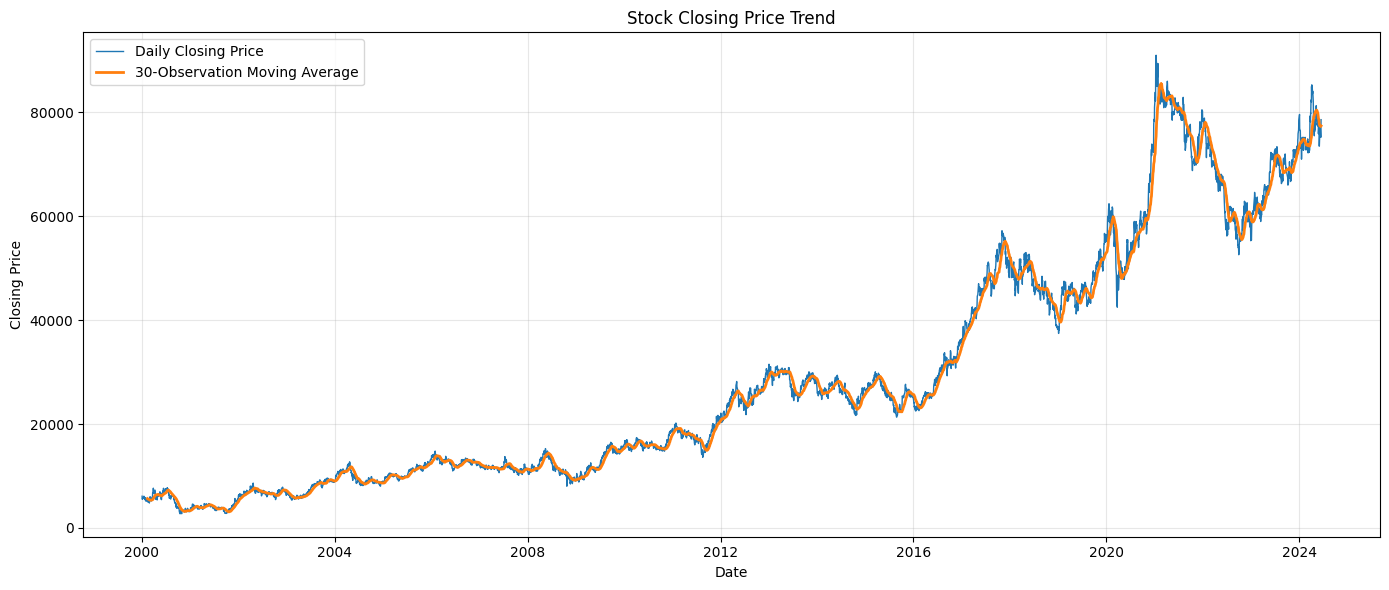

In [25]:

plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["Close"],
    label="Daily Closing Price",
    linewidth=1
)

# 30-observation moving average
data["MA_30"] = data["Close"].rolling(30).mean()

plt.plot(
    data.index,
    data["MA_30"],
    label="30-Observation Moving Average",
    linewidth=2
)

plt.title("Stock Closing Price Trend")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



# Monthly Average Closing Price

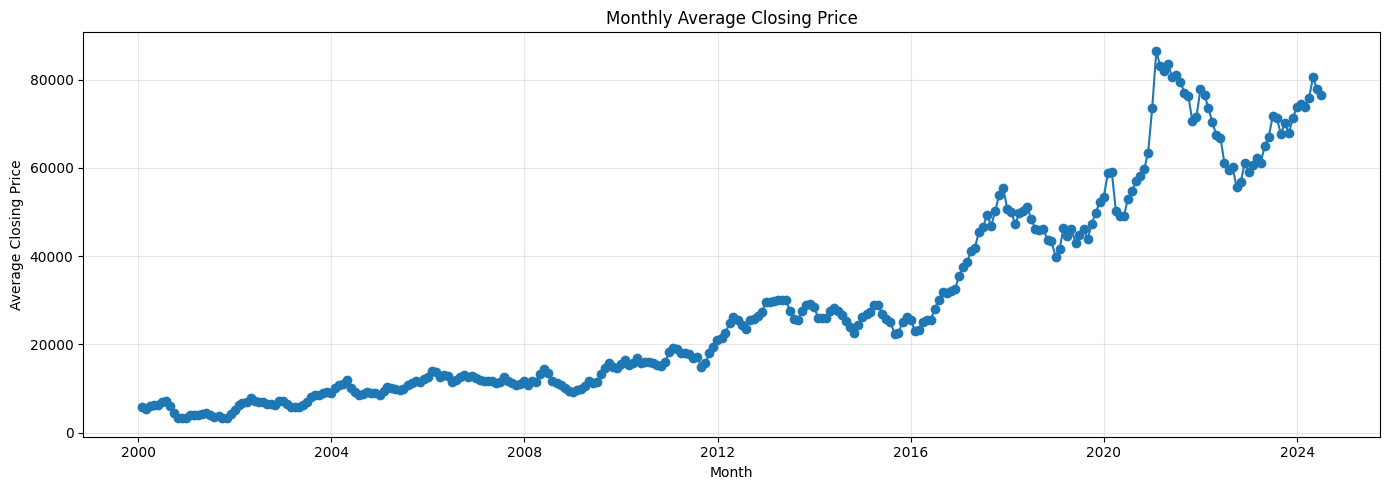

In [26]:
monthly_close = data["Close"].resample("ME").mean()

plt.figure(figsize=(14, 5))
plt.plot(monthly_close.index, monthly_close.values, marker="o")

plt.title("Monthly Average Closing Price")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Daily Returns Analysis

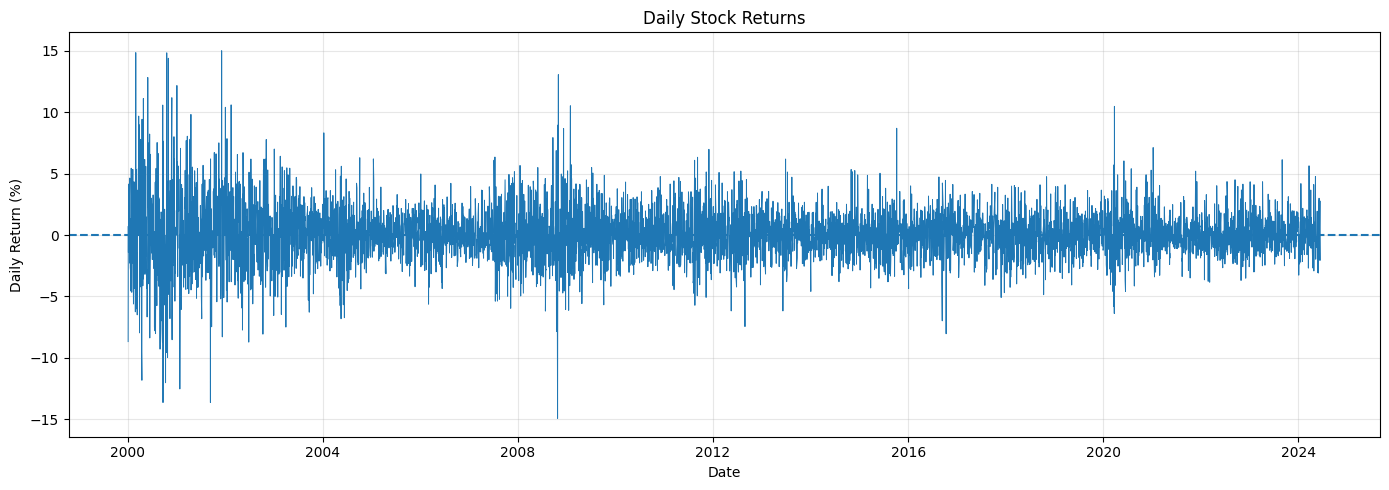

In [27]:
data["Daily_Return_%"] = data["Close"].pct_change() * 100

plt.figure(figsize=(14, 5))
plt.plot(
    data.index,
    data["Daily_Return_%"],
    linewidth=0.7
)

plt.axhline(0, linestyle="--")
plt.title("Daily Stock Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Seasonality Detection

C:\Users\hp\AppData\Local\Temp\ipykernel_7364\1413858907.py:4: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(


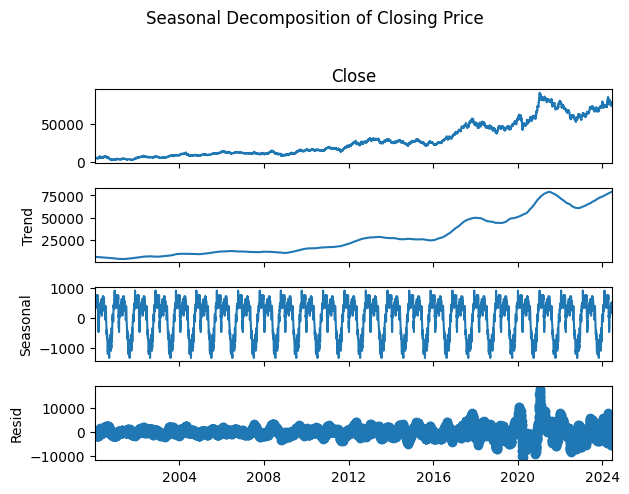


Seasonality decomposition completed.
Period used: 252 observations (approx. trading year)


In [28]:
if len(data) >= 504:
    series = data["Close"].dropna()

    decomposition = seasonal_decompose(
        series,
        model="additive",
        period=252,
        extrapolate_trend="freq"
    )

    decomposition.plot()
    plt.suptitle(
        "Seasonal Decomposition of Closing Price",
        y=1.02
    )
    plt.tight_layout()
    plt.show()

    print("\nSeasonality decomposition completed.")
    print("Period used: 252 observations (approx. trading year)")
else:
    print("\nNot enough observations for annual decomposition.")

# Month-of-Year Pattern

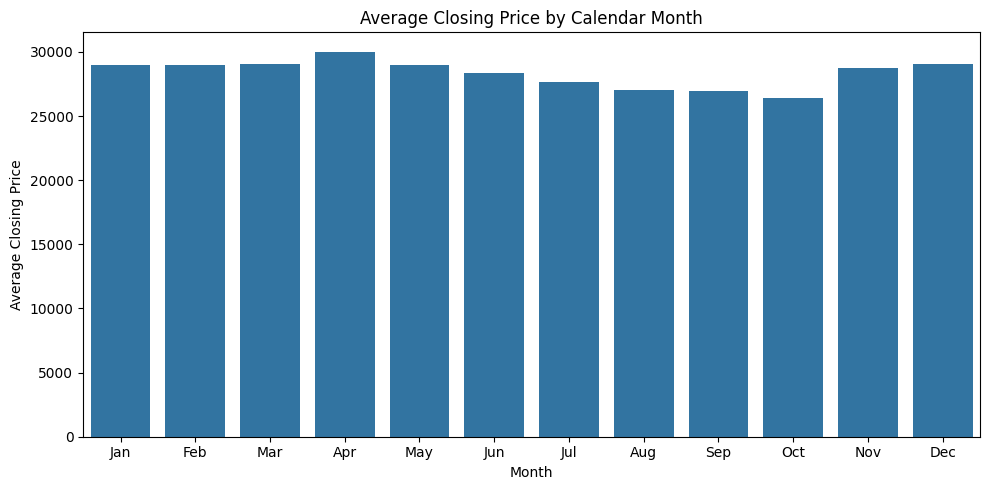


Average Closing Price by Month:
Jan    28996.27
Feb    28974.82
Mar    29068.66
Apr    30027.56
May    28956.04
Jun    28357.87
Jul    27654.82
Aug    27060.52
Sep    26927.75
Oct    26371.17
Nov    28721.98
Dec    29047.26
Name: Close, dtype: float64


In [29]:
monthly_pattern = data["Close"].groupby(
    data.index.month
).mean()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_pattern.index = [
    month_names[m - 1] for m in monthly_pattern.index
]

plt.figure(figsize=(10, 5))
sns.barplot(
    x=monthly_pattern.index,
    y=monthly_pattern.values
)

plt.title("Average Closing Price by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.tight_layout()
plt.show()

print("\nAverage Closing Price by Month:")
print(monthly_pattern.round(2))


# 8. Trend and Volatility Statistics

In [30]:
first_close = data["Close"].iloc[0]
last_close = data["Close"].iloc[-1]

overall_change = (
    (last_close - first_close) / first_close
) * 100 if first_close != 0 else np.nan

daily_returns = data["Close"].pct_change().dropna()

annualized_volatility = (
    daily_returns.std() * np.sqrt(252) * 100
)

print("\n========== TIME SERIES SUMMARY ==========")
print("First Closing Price:", round(first_close, 2))
print("Last Closing Price:", round(last_close, 2))
print("Overall Price Change (%):", round(overall_change, 2))
print("Highest Closing Price:", round(data["Close"].max(), 2))
print("Lowest Closing Price:", round(data["Close"].min(), 2))
print("Average Closing Price:", round(data["Close"].mean(), 2))
print(
    "Annualized Historical Volatility (%):",
    round(annualized_volatility, 2)
)



========== TIME SERIES SUMMARY ==========
First Closing Price: 6110.0
Last Closing Price: 78600.0
Overall Price Change (%): 1186.42
Highest Closing Price: 91000.0
Lowest Closing Price: 2730.0
Average Closing Price: 28360.01
Annualized Historical Volatility (%): 34.31


# Stationarity Test 

In [32]:
adf_result = adfuller(data["Close"].dropna())

print("\n========== AUGMENTED DICKEY-FULLER TEST ==========")
print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] < 0.05:
    print("Result: Evidence of stationarity at the 5% level.")
else:
    print("Result: Evidence is insufficient to conclude stationarity.")


========== AUGMENTED DICKEY-FULLER TEST ==========
ADF Statistic: 0.1634
p-value: 0.9701
Result: Evidence is insufficient to conclude stationarity.


C:\Users\hp\AppData\Local\Temp\ipykernel_7364\2410613241.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(data["Close"].dropna())


# Optional: Simple 30-Day Forecast

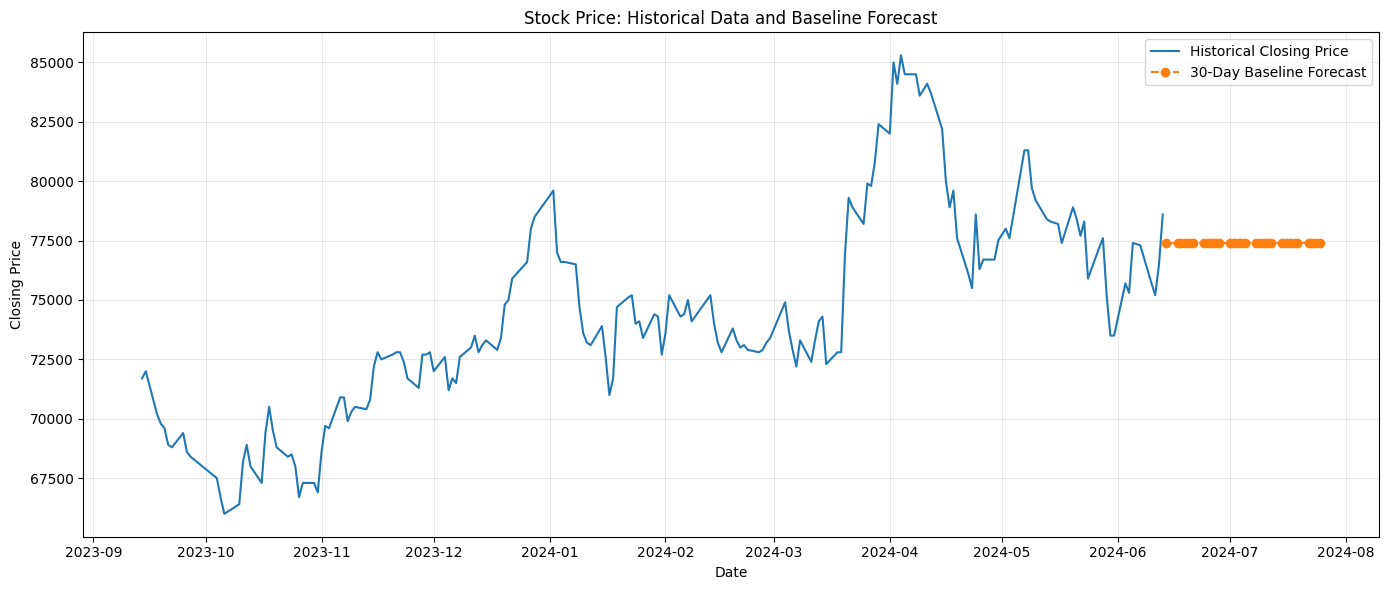


Forecast Method: Last 30 observations' average
Forecast Period: 30 business days
Forecast Closing Price: 77383.33


In [33]:
forecast_days = 30
last_date = data.index.max()

future_dates = pd.bdate_range(
    start=last_date + pd.offsets.BDay(1),
    periods=forecast_days
)

forecast_value = data["Close"].tail(30).mean()

forecast = pd.Series(
    forecast_value,
    index=future_dates
)

plt.figure(figsize=(14, 6))

plt.plot(
    data.index[-180:],
    data["Close"].tail(180),
    label="Historical Closing Price"
)

plt.plot(
    forecast.index,
    forecast.values,
    linestyle="--",
    marker="o",
    label="30-Day Baseline Forecast"
)

plt.title("Stock Price: Historical Data and Baseline Forecast")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nForecast Method: Last 30 observations' average")
print("Forecast Period:", len(forecast), "business days")
print("Forecast Closing Price:", round(forecast_value, 2))



# 11. Save Analysis Results

In [34]:
data.to_csv("stock_time_series_analysis.csv")
forecast.to_csv("stock_price_forecast.csv", header=["Forecast_Close"])

print("\nFiles Saved Successfully:")
print("1. stock_time_series_analysis.csv")
print("2. stock_price_forecast.csv")


Files Saved Successfully:
1. stock_time_series_analysis.csv
2. stock_price_forecast.csv
